# Exploración de datos — Pruebas Saber 11

**Proyecto del curso Despliegue de Soluciones Analíticas · MIAD**

Este cuaderno explora los resultados individuales de las pruebas Saber 11 del ICFES
para los periodos 2020-1 y 2020-2, obtenidos del portal de Datos Abiertos de Colombia
(`www.datos.gov.co`) a través de la API de Socrata.

El objetivo es doble: caracterizar la calidad y el contenido de los datos, y evaluar
**a qué nivel de agregación** existe una señal suficientemente fuerte para sostener un
producto analítico.

> Los datos no están en el repositorio: se gestionan con DVC. Si falta el archivo,
> ejecute `dvc pull` antes de correr este cuaderno.

## 1. Configuración

Una única definición de la paleta y los estilos, para que todas las figuras del
reporte se lean como un solo sistema.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")

# Raiz del proyecto: funciona ejecutando desde notebooks/ o desde la raiz
RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
FIGURAS = RAIZ / "reports" / "figures"
FIGURAS.mkdir(parents=True, exist_ok=True)

# Paleta: una sola fuente de verdad para todas las figuras
SUPERFICIE, TINTA, TINTA_2, TINTA_MUDA = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
REJILLA, EJE = "#e1e0d9", "#c3c2b7"
AZUL, NARANJA, ROJO = "#2a78d6", "#eb6834", "#e34948"
RAMPA_AZUL = LinearSegmentedColormap.from_list(
    "azul", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

mpl.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE,
    "savefig.facecolor": SUPERFICIE, "figure.dpi": 96, "savefig.dpi": 200,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "font.size": 9.5, "text.color": TINTA, "axes.labelcolor": TINTA_2,
    "axes.titlecolor": TINTA, "xtick.color": TINTA_MUDA, "ytick.color": TINTA_MUDA,
    "axes.edgecolor": EJE, "axes.linewidth": 0.8,
    "grid.color": REJILLA, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlepad": 12,
    "legend.frameon": False,
})

def miles(n):
    """Separador de miles con punto, como se usa en Colombia."""
    return f"{n:,}".replace(",", ".")

def guardar(fig, nombre):
    fig.savefig(FIGURAS / f"{nombre}.png", bbox_inches="tight")
    print(f"guardada -> reports/figures/{nombre}.png")

print("Entorno listo |", RAIZ.name)

Entorno listo | Project


## 2. Carga de los datos

El conjunto completo tiene 82 variables. Se cargan las 27 relevantes para esta
exploración: resultados, características del estudiante, del hogar y del
establecimiento.

In [2]:
RUTA = RAIZ / "data" / "raw" / "saber_11_2020_1_2.parquet"
assert RUTA.exists(), "Falta el parquet. Corre:  dvc pull"

NUMERICAS = ["punt_global", "punt_lectura_critica", "punt_matematicas", "punt_c_naturales",
             "punt_sociales_ciudadanas", "punt_ingles", "estu_inse_individual",
             "estu_nse_individual", "estu_nse_establecimiento"]
CATEGORICAS = ["periodo", "estu_genero", "estu_depto_reside", "estu_estadoinvestigacion",
               "fami_estratovivienda", "fami_educacionmadre", "fami_educacionpadre",
               "fami_numlibros", "fami_tieneinternet", "fami_tienecomputador",
               "cole_naturaleza", "cole_area_ubicacion", "cole_jornada", "cole_calendario",
               "cole_bilingue", "cole_depto_ubicacion", "estu_generacion_e"]
IDS = ["cole_cod_dane_establecimiento"]

df = pd.read_parquet(RUTA, columns=NUMERICAS + CATEGORICAS + IDS)
print(f"Registros: {len(df):,}   Columnas cargadas: {df.shape[1]} (de 82 disponibles)")
print(f"Memoria como texto crudo: {df.memory_usage(deep=True).sum()/2**20:,.0f} MB")

Registros: 520,307   Columnas cargadas: 27 (de 82 disponibles)


Memoria como texto crudo: 862 MB


## 3. Tipificación

La API de Socrata entrega **todas** las columnas como texto, incluidos los puntajes.
Convertirlas al tipo correcto no es solo cosmética: reduce el uso de memoria en un
orden de magnitud y habilita las operaciones estadísticas.

In [3]:
# El API de Socrata entrega las 82 columnas como texto, sin excepcion.
for c in NUMERICAS:
    df[c] = pd.to_numeric(df[c], errors="coerce")
for c in CATEGORICAS:
    df[c] = df[c].astype("category")

print(f"Memoria tras tipificar: {df.memory_usage(deep=True).sum()/2**20:,.0f} MB")
df[["punt_global", "estu_inse_individual", "cole_naturaleza"]].dtypes.to_frame("tipo")

Memoria tras tipificar: 78 MB


,tipo
punt_global,int64
estu_inse_individual,float64
cole_naturaleza,category


## 4. Calidad de los datos

Antes de analizar nada, conviene saber con qué se cuenta.

In [4]:
nulos = (df.isna().mean() * 100).round(2).sort_values(ascending=False)
calidad = pd.DataFrame({"% faltantes": nulos})
calidad = calidad[calidad["% faltantes"] > 0]

print(f"Columnas sin ningun faltante: {(nulos == 0).sum()} de {len(nulos)}")
print(f"Filas duplicadas completas:   {df.duplicated().sum()}")
print(f"\nRegistros bajo investigacion de validez: "
      f"{(df.estu_estadoinvestigacion != 'PUBLICAR').sum()}")
calidad

Columnas sin ningun faltante: 15 de 27


Filas duplicadas completas:   2

Registros bajo investigacion de validez: 260


,% faltantes
cole_bilingue,16.46
estu_nse_individual,5.65
estu_inse_individual,5.65
fami_tienecomputador,4.15
fami_estratovivienda,3.56
fami_numlibros,3.00
estu_nse_establecimiento,2.98
fami_tieneinternet,2.92
fami_educacionmadre,2.89
fami_educacionpadre,2.79


La calidad es alta: la mayoría de columnas no tiene un solo faltante y los duplicados
son anecdóticos. Los faltantes se concentran en variables declaradas por el estudiante
(bienes del hogar, educación de los padres), donde el no-reporte es en sí mismo
informativo y conviene tratarlo como categoría propia antes que imputarlo.

## 5. La variable objetivo

`punt_global` resume el desempeño en las cinco áreas evaluadas, en escala de 0 a 500.

In [5]:
objetivo = df.punt_global
print("Variable objetivo: punt_global (escala 0 a 500)")
print(objetivo.describe().round(1).to_string())
print(f"\nValores en cero:        {(objetivo == 0).sum()}")
print(f"Valores por debajo 100: {(objetivo < 100).sum()}")
print(f"Faltantes:              {objetivo.isna().sum()}")

Variable objetivo: punt_global (escala 0 a 500)
count    520307.0
mean        249.6
std          49.6
min           0.0
25%         212.0
50%         246.0
75%         283.0
max         500.0

Valores en cero:        81
Valores por debajo 100: 238
Faltantes:              0


Existe un grupo reducido de puntajes en cero o muy bajos. Junto con los registros
marcados bajo investigación de validez, son candidatos a excluirse del modelamiento;
la decisión debe documentarse explícitamente.

## 6. Los dos periodos no son comparables

El archivo mezcla dos aplicaciones de la prueba. Antes de analizarlas juntas hay que
verificar que midan lo mismo.

In [6]:
periodos = df.groupby("periodo", observed=True)["punt_global"].agg(
    ["count", "mean", "std", "median"]).round(1)
periodos.columns = ["registros", "media", "desv.", "mediana"]
print(periodos.to_string())
print(f"\nDiferencia de medias: {periodos['media'].max() - periodos['media'].min():.1f} puntos")

         registros  media  desv.  mediana
periodo                                  
20201        15435  289.4   60.3    295.0
20204       504872  248.3   48.7    245.0

Diferencia de medias: 41.1 puntos


La diferencia es grande y el desbalance también: 2020-1 corresponde a los colegios de
calendario B, un subconjunto pequeño y socioeconómicamente distinto, evaluado antes de
la pandemia. Tratarlos como una sola población introduciría un sesgo difícil de
justificar.

**Decisión de alcance:** el análisis se concentra en **2020-2**, la cohorte masiva.
El periodo 2020-1 queda disponible como conjunto de validación externa.

In [7]:
d = df[df.periodo == "20204"].copy()
print(f"Cohorte de analisis (2020-2): {len(d):,} registros "
      f"({len(d)/len(df)*100:.1f}% del total)")

Cohorte de analisis (2020-2): 504,872 registros (97.0% del total)


## 7. Brechas entre grupos poblacionales

Para cada variable se compara el grupo con mayor y menor puntaje promedio. Se exigen
al menos 500 estudiantes por grupo para evitar que categorías marginales dominen la
comparación.

In [8]:
def resumen_grupo(col, minimo=500):
    g = d.groupby(col, observed=True)["punt_global"].agg(["count", "mean"])
    g = g[g["count"] >= minimo].sort_values("mean")
    return g.round(1)

VARIABLES = {
    "fami_educacionmadre":   "Educación de la madre",
    "cole_jornada":          "Jornada del colegio",
    "fami_estratovivienda":  "Estrato de la vivienda",
    "fami_numlibros":        "Libros en el hogar",
    "fami_tieneinternet":    "Internet en el hogar",
    "fami_tienecomputador":  "Computador en el hogar",
    "cole_naturaleza":       "Naturaleza del colegio",
    "cole_area_ubicacion":   "Ubicación del colegio",
    "estu_genero":           "Género del estudiante",
}

filas = []
for col, etiqueta in VARIABLES.items():
    g = resumen_grupo(col)
    filas.append({"Variable": etiqueta,
                  "Brecha (pts)": round(g["mean"].iloc[-1] - g["mean"].iloc[0], 1),
                  "Mínimo": g.index[0], "Media mín.": g["mean"].iloc[0],
                  "Máximo": g.index[-1], "Media máx.": g["mean"].iloc[-1]})

brechas = pd.DataFrame(filas).sort_values("Brecha (pts)", ascending=False).reset_index(drop=True)
brechas

,Variable,Brecha (pts),Mínimo,Media mín.,Máximo,Media máx.
0,Educación de la madre,90.9,Ninguno,212.4,Postgrado,303.3
1,Jornada del colegio,64.2,NOCHE,211.6,COMPLETA,275.8
2,Estrato de la vivienda,63.4,Sin Estrato,209.6,Estrato 4,273.0
3,Libros en el hogar,38.9,0 A 10 LIBROS,233.8,MÁS DE 100 LIBROS,272.7
4,Internet en el hogar,32.1,No,226.3,Si,258.4
5,Computador en el hogar,30.9,No,230.1,Si,261.0
6,Naturaleza del colegio,29.0,OFICIAL,241.8,NO OFICIAL,270.8
7,Ubicación del colegio,25.4,RURAL,227.1,URBANO,252.5
8,Género del estudiante,7.1,F,245.1,M,252.2


guardada -> reports/figures/01_brechas_por_grupo.png


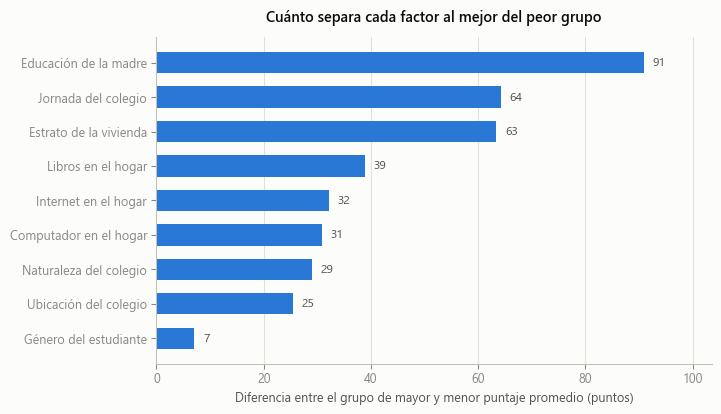

In [9]:
fig, ax = plt.subplots(figsize=(7.4, 4.2), constrained_layout=True)
orden = brechas.sort_values("Brecha (pts)")
barras = ax.barh(orden["Variable"], orden["Brecha (pts)"], color=AZUL, height=0.62)

for barra, valor in zip(barras, orden["Brecha (pts)"]):
    ax.text(valor + 1.6, barra.get_y() + barra.get_height()/2, f"{valor:.0f}",
            va="center", ha="left", color=TINTA_2, fontsize=9)

ax.set_xlabel("Diferencia entre el grupo de mayor y menor puntaje promedio (puntos)")
ax.set_title("Cuánto separa cada factor al mejor del peor grupo")
ax.set_xlim(0, orden["Brecha (pts)"].max() * 1.14)
ax.xaxis.grid(True); ax.yaxis.grid(False); ax.set_axisbelow(True)
ax.spines["left"].set_color(EJE)
guardar(fig, "01_brechas_por_grupo")
plt.show()

Dos lecturas que vale la pena señalar:

- **La educación de la madre pesa más que el estrato, el tipo de colegio o la
  ubicación.** Es el predictor individual más fuerte del conjunto.
- **La jornada del colegio produce una brecha de magnitud comparable al estrato.**
  A diferencia de las variables del hogar, la jornada es una característica del
  sistema educativo y, por tanto, susceptible de intervención.

La brecha de género es menor que cualquier variable socioeconómica y se concentra en
matemáticas.

### La escala educativa de la madre, en detalle

guardada -> reports/figures/02_educacion_madre.png


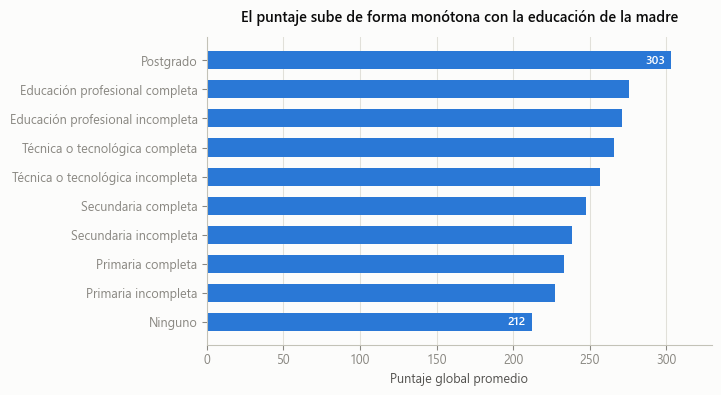

Brecha extremo a extremo: 90.9 puntos


In [10]:
ESCALA_EDUCATIVA = [
    "Ninguno", "Primaria incompleta", "Primaria completa",
    "Secundaria (Bachillerato) incompleta", "Secundaria (Bachillerato) completa",
    "Técnica o tecnológica incompleta", "Técnica o tecnológica completa",
    "Educación profesional incompleta", "Educación profesional completa", "Postgrado",
]
madre = (d[d.fami_educacionmadre.isin(ESCALA_EDUCATIVA)]
         .groupby("fami_educacionmadre", observed=True)["punt_global"]
         .agg(["count", "mean"]).reindex(ESCALA_EDUCATIVA).dropna())

fig, ax = plt.subplots(figsize=(7.4, 4.0), constrained_layout=True)
barras = ax.barh(range(len(madre)), madre["mean"], color=AZUL, height=0.62)
ax.set_yticks(range(len(madre)))
ax.set_yticklabels([e.replace(" (Bachillerato)", "") for e in madre.index])

# Etiqueta solo los extremos: el resto lo lleva el eje
for i in (0, len(madre) - 1):
    ax.text(madre["mean"].iloc[i] - 4, i, f"{madre['mean'].iloc[i]:.0f}",
            va="center", ha="right", color="#ffffff", fontsize=9, fontweight="semibold")

ax.set_xlabel("Puntaje global promedio")
ax.set_title("El puntaje sube de forma monótona con la educación de la madre")
ax.set_xlim(0, 330)
ax.xaxis.grid(True); ax.yaxis.grid(False); ax.set_axisbelow(True)
ax.spines["left"].set_color(EJE)
guardar(fig, "02_educacion_madre")
plt.show()
print(f"Brecha extremo a extremo: {madre['mean'].iloc[-1] - madre['mean'].iloc[0]:.1f} puntos")

La relación es monótona y sin saltos: cada nivel educativo adicional de la madre se
asocia con un puntaje mayor. El salto más pronunciado ocurre al llegar a posgrado.

## 8. El hallazgo central: el nivel de agregación

Las brechas anteriores son nítidas en promedio, pero ¿alcanzan para predecir el
resultado de **un** estudiante? La pregunta no es retórica: determina qué producto es
viable construir.

Comparamos la misma relación —índice socioeconómico contra puntaje— a nivel de
estudiante y a nivel de colegio.

In [11]:
# Agregacion a nivel de establecimiento educativo
colegios = (d.groupby("cole_cod_dane_establecimiento", observed=True)
              .agg(estudiantes=("punt_global", "size"),
                   media=("punt_global", "mean"),
                   inse=("estu_inse_individual", "mean"))
              .dropna())
colegios = colegios[colegios.estudiantes >= 20]

ind = d[["estu_inse_individual", "punt_global"]].dropna()
r_individual = ind.corr().iloc[0, 1]
r_colegio = np.corrcoef(colegios.inse, colegios.media)[0, 1]

print(f"Colegios con 20 o mas estudiantes: {miles(len(colegios))}")
print(f"\nCorrelacion INSE - puntaje")
print(f"  a nivel estudiante : r = {r_individual:.3f}   R2 = {r_individual**2:.3f}")
print(f"  a nivel colegio    : r = {r_colegio:.3f}   R2 = {r_colegio**2:.3f}")

Colegios con 20 o mas estudiantes: 6.990

Correlacion INSE - puntaje
  a nivel estudiante : r = 0.451   R2 = 0.203
  a nivel colegio    : r = 0.802   R2 = 0.644


guardada -> reports/figures/03_individual_vs_colegio.png


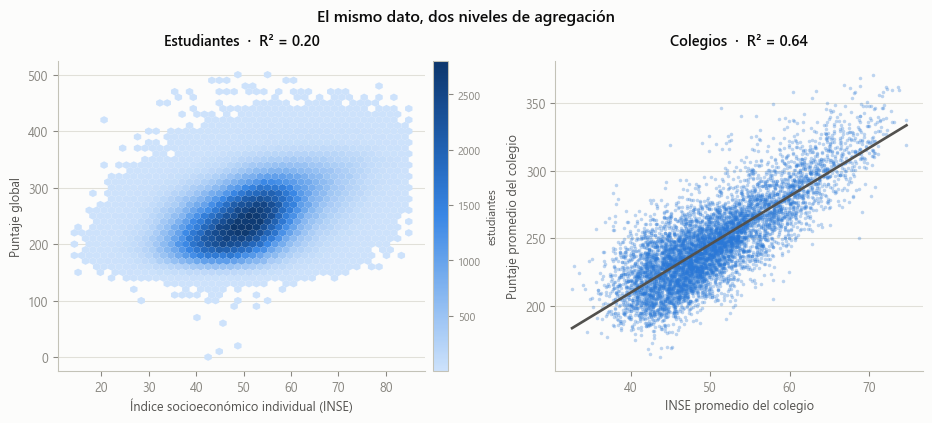

In [12]:
fig, (iz, de) = plt.subplots(1, 2, figsize=(9.6, 4.3), constrained_layout=True)

# Panel izquierdo: densidad, porque 490 mil puntos se solapan hasta ser ilegibles
hb = iz.hexbin(ind.estu_inse_individual, ind.punt_global, gridsize=45,
               cmap=RAMPA_AZUL, mincnt=1, linewidths=0)
iz.set_title(f"Estudiantes  ·  R² = {r_individual**2:.2f}")
iz.set_xlabel("Índice socioeconómico individual (INSE)")
iz.set_ylabel("Puntaje global")
barra = fig.colorbar(hb, ax=iz, pad=0.02)
barra.set_label("estudiantes", color=TINTA_2, fontsize=8.5)
barra.outline.set_edgecolor(EJE)
barra.ax.tick_params(colors=TINTA_MUDA, labelsize=8)

# Panel derecho: ya son 6.990 marcas, el scatter respira
de.scatter(colegios.inse, colegios.media, s=7, color=AZUL, alpha=0.30, linewidths=0)
pend, corte = np.polyfit(colegios.inse, colegios.media, 1)
ejex = np.linspace(colegios.inse.min(), colegios.inse.max(), 100)
de.plot(ejex, corte + pend * ejex, color=TINTA_2, linewidth=2)
de.set_title(f"Colegios  ·  R² = {r_colegio**2:.2f}")
de.set_xlabel("INSE promedio del colegio")
de.set_ylabel("Puntaje promedio del colegio")

for ax in (iz, de):
    ax.grid(True, axis="y"); ax.set_axisbelow(True)

fig.suptitle("El mismo dato, dos niveles de agregación", fontsize=12,
             fontweight="semibold", color=TINTA)
guardar(fig, "03_individual_vs_colegio")
plt.show()

El contraste es grande. A nivel individual el contexto socioeconómico explica cerca de
una quinta parte de la variación: hay tanta dispersión que predecir el puntaje de un
estudiante concreto a partir de su perfil resulta poco informativo, y además sería
cuestionable usarlo para clasificar personas.

Al agregar por colegio, el ruido individual se promedia y emerge una relación fuerte.
Esto reorienta el producto: **la unidad de análisis útil es el establecimiento, no el
estudiante.**

## 9. Lo que el contexto no explica

Si el perfil socioeconómico explica buena parte del desempeño de un colegio, lo
interesante es precisamente lo que *no* explica: colegios que rinden sistemáticamente
por encima o por debajo de lo que su contexto haría esperar.

El residual —la distancia entre el puntaje observado y el esperado— es esa medida.

In [13]:
colegios["esperado"] = corte + pend * colegios.inse
colegios["residual"] = colegios.media - colegios.esperado
sigma = colegios.residual.std()

sobre = colegios.residual > sigma
bajo = colegios.residual < -sigma
print(f"Desviacion del residual: {sigma:.1f} puntos")
print(f"Rango: {colegios.residual.min():.1f} a {colegios.residual.max():.1f}")
print(f"\nColegios mas de 1 desviacion POR ENCIMA de lo esperado: {miles(sobre.sum())}")
print(f"Colegios mas de 1 desviacion POR DEBAJO de lo esperado: {miles(bajo.sum())}")
print(f"Entre ambos: {miles(sobre.sum() + bajo.sum())} de {miles(len(colegios))} "
      f"({(sobre.sum() + bajo.sum())/len(colegios)*100:.0f}%)")

Desviacion del residual: 19.1 puntos
Rango: -68.2 a 95.7

Colegios mas de 1 desviacion POR ENCIMA de lo esperado: 1.017
Colegios mas de 1 desviacion POR DEBAJO de lo esperado: 1.061
Entre ambos: 2.078 de 6.990 (30%)


guardada -> reports/figures/04_valor_agregado_colegios.png


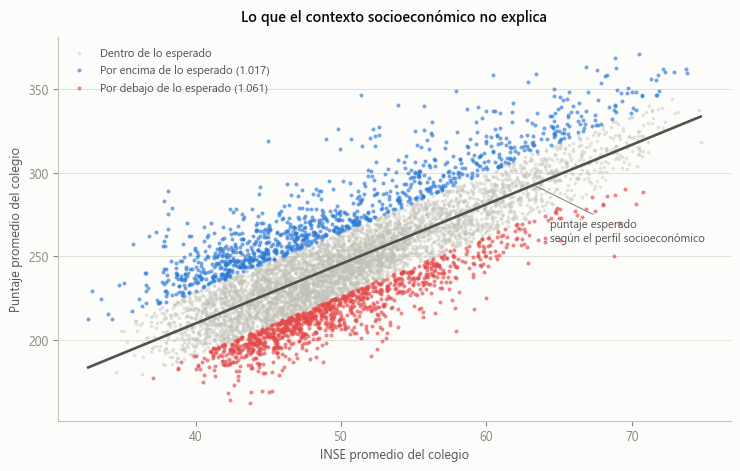

In [14]:
fig, ax = plt.subplots(figsize=(7.6, 4.8), constrained_layout=True)

neutro = ~(sobre | bajo)
ax.scatter(colegios.inse[neutro], colegios.media[neutro], s=7,
           color=EJE, alpha=0.45, linewidths=0, label="Dentro de lo esperado")
ax.scatter(colegios.inse[sobre], colegios.media[sobre], s=9,
           color=AZUL, alpha=0.65, linewidths=0,
           label=f"Por encima de lo esperado ({miles(sobre.sum())})")
ax.scatter(colegios.inse[bajo], colegios.media[bajo], s=9,
           color=ROJO, alpha=0.65, linewidths=0,
           label=f"Por debajo de lo esperado ({miles(bajo.sum())})")
ax.plot(ejex, corte + pend * ejex, color=TINTA_2, linewidth=2, zorder=5)
ax.annotate("puntaje esperado\nsegún el perfil socioeconómico",
            xy=(ejex[72], corte + pend * ejex[72]), xytext=(12, -42),
            textcoords="offset points", fontsize=8.5, color=TINTA_2,
            arrowprops=dict(arrowstyle="-", color=TINTA_MUDA, linewidth=0.8))

ax.set_xlabel("INSE promedio del colegio")
ax.set_ylabel("Puntaje promedio del colegio")
ax.set_title("Lo que el contexto socioeconómico no explica")
ax.grid(True, axis="y"); ax.set_axisbelow(True)
ax.legend(loc="upper left", fontsize=8.5, labelcolor=TINTA_2)
guardar(fig, "04_valor_agregado_colegios")
plt.show()

Alrededor de dos mil colegios se apartan más de una desviación estándar de su
expectativa. Son establecimientos donde ocurre algo que el contexto socioeconómico no
captura: prácticas que valdría la pena documentar en un extremo, y necesidad de apoyo
en el otro.

Es una magnitud accionable, y se concentra en unidades —los colegios— sobre las que una
autoridad educativa sí puede intervenir.

## 10. Conclusiones para el diseño del producto

1. **Los datos son aptos.** Calidad alta, faltantes concentrados y explicables,
   cobertura nacional de 33 departamentos y más de diez mil establecimientos.

2. **El alcance se limita a 2020-2.** Los dos periodos del archivo no son comparables
   y mezclarlos sesgaría cualquier modelo.

3. **Las brechas socioeconómicas son grandes y consistentes**, y la educación de la
   madre es el factor individual más fuerte.

4. **El nivel de agregación define el producto.** A nivel estudiante la señal es débil;
   a nivel colegio es fuerte. Un producto construido sobre predicción individual sería
   poco útil y éticamente discutible; uno construido sobre el desempeño relativo de los
   establecimientos tiene señal estadística y un destinatario claro.

5. **El residual es el insumo accionable**, no la predicción en sí misma.

### Pendientes

- Incorporar periodos adicionales con `src/data/descargar_datos.py` para analizar la
  evolución en el tiempo.
- Revisar la no-monotonía observada en los estratos altos.
- Definir el tratamiento de los puntajes en cero y de los registros bajo investigación.